# 04 Auswertung

Dieses Notebook wertet die drei Experimente aus Notebook 03 aus. Es liest ausschließlich die CSV-Dateien in `results/<experiment>/runs/` und trainiert nichts. Die Abbildungen werden zusätzlich als PNG in `figures/` gespeichert.

Ausgewertet werden nur Seeds, für die alle fünf Varianten fertig sind (`load_complete` in `analysis.py`). So bleiben alle Vergleiche gepaart: Jede Differenz wird zwischen zwei Läufen mit identischen Startgewichten gebildet.

## Kennzahlen

Pro Lauf berechnet `run_metrics` in `analysis.py`:

| Kennzahl | Bedeutung                                                                                            |
|---|------------------------------------------------------------------------------------------------------|
| `best_val_acc` | höchste Val-Accuracy über alle Epochen                                                               |
| `best_val_acc_epoch` | Epoche, in der sie erreicht wird                                                                     |
| `test_acc_at_best` | Test-Accuracy in dieser Epoche (unverzerrte Schätzung, weil die Epoche anhand von Val gewählt wurde) |
| `min_val_loss`, `min_val_loss_epoch` | niedrigster Val-Loss und seine Epoche                                                                |
| `gap_last_epoch` | Generalization Gap: Val-Loss − Train-Loss in der letzten Epoche                                      |
| `acc_gap_last_epoch` | Train-Accuracy − Val-Accuracy in der letzten Epoche                                                  |
| `val_loss_at_common_train_loss` | Val-Loss in dem Moment, in dem der Train-Loss ein gemeinsames Niveau erreicht                        |

Zur letzten Kennzahl: Varianten, die schneller lernen, haben in derselben Epoche einen kleineren Train-Loss. Ein Gap in einer festen Epoche vergleicht deshalb Modelle mit unterschiedlichem Trainingsstand. Fairer ist es, den Val-Loss bei gleicher Anpassung an die Trainingsdaten zu vergleichen. Das gemeinsame Niveau (`common_train_loss`) ist der größte End-Train-Loss unter allen Läufen von A-D; jeder Lauf erreicht es also irgendwann. Der Val-Loss an dieser Stelle wird zwischen den zwei benachbarten Epochen interpoliert (`val_loss_at_train_loss`). E ist hier ausgenommen, weil es dieses Niveau nicht erreicht.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.pyplot import xscale

from batch_shuffling_regularization.analysis import SHUFFLE_VARIANTS, VARIANT_NAMES, common_train_loss, load_complete, paired_comparison, run_metrics
from batch_shuffling_regularization.experiment import EXPERIMENTS, RESULTS_DIR

FIG_DIR = RESULTS_DIR.parent / "figures"
FIG_DIR.mkdir(exist_ok=True)

COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a", "D": "#eda100", "E": "#e87ba4"}
STYLES = {"C": "--"}
TITLES = {"mnist_bs100": "MNIST, Batchgröße 100", "mnist_bs10": "MNIST, Batchgröße 10", "fashion_bs100": "Fashion-MNIST, Batchgröße 100"}


def style_axes(ax: plt.Axes) -> None:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Daten laden

In [2]:
results = {name: load_complete(experiment) for name, experiment in EXPERIMENTS.items()}
levels = {name: common_train_loss(df) for name, df in results.items()}
metrics = {name: run_metrics(df, levels[name]) for name, df in results.items()}

pd.DataFrame(
    {
        "ausgewertete Seeds": {name: df["seed"].nunique() for name, df in results.items()},
        "gemeinsames Train-Loss-Niveau": levels,
    }
)

,ausgewertete Seeds,gemeinsames Train-Loss-Niveau
mnist_bs100,20,0.000856
mnist_bs10,20,0.000842
fashion_bs100,20,0.149776


Falls ein Experiment noch nicht alle 20 Seeds hat, werden nur die fertigen Seeds ausgewertet. Die Aussagen für dieses Experiment sind dann entsprechend unsicherer.

Aktuell sind alle drei Experimente mit 20 Seeds vollständig. Die Texte unter **Ergebnis** beziehen sich auf diesen Stand. Das gemeinsame Train-Loss-Niveau liegt bei MNIST unter 0,001, bei Fashion-MNIST bei ~0,15: Dort ist das Netz nach 30 Epochen noch weit davon entfernt, die Trainingsdaten auswendig zu kennen.

## 1 Lernkurven

Train- und Val-Loss pro Epoche für A-D, Mittelwert über die Seeds, die Fläche zeigt ± eine Standardabweichung. E fehlt hier, weil sein Loss um ein Vielfaches höher liegt; er hat einen eigenen Abschnitt (6).

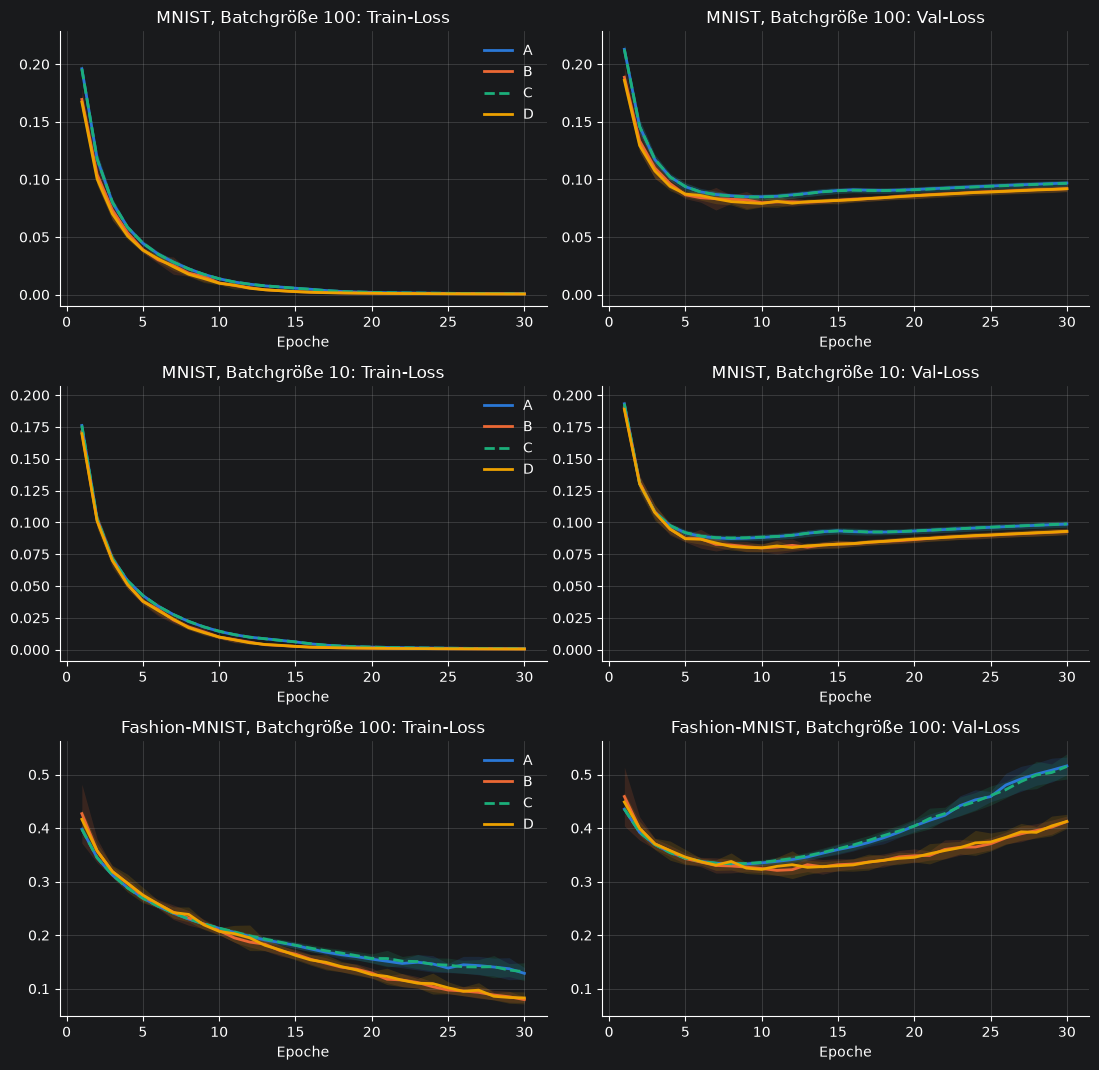

In [3]:
fig, axes = plt.subplots(len(results), 2, figsize=(11, 3.6 * len(results)), squeeze=False, sharey='row')
for row, (name, df) in enumerate(results.items()):
    for col, column in enumerate(["train_loss", "val_loss"]):
        ax = axes[row, col]
        for variant in SHUFFLE_VARIANTS:
            curve = df[(df["variant"] == variant) & (df["epoch"] > 0)].groupby("epoch")[column].agg(["mean", "std"])
            ax.plot(curve.index, curve["mean"], STYLES.get(variant, "-"), color=COLORS[variant], lw=2, label=variant)
            ax.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], color=COLORS[variant], alpha=0.15, lw=0)
        ax.set(xlabel="Epoche", title=f"{TITLES[name]}: {'Train' if column == 'train_loss' else 'Val'}-Loss")
        ax.tick_params(labelleft=True)
        style_axes(ax)
    axes[row, 0].legend(frameon=False)
fig.tight_layout()
save(fig, "learning_curves")

Lesehilfe: Der Train-Loss fällt immer weiter, während der Val-Loss nach einigen Epochen sein Minimum erreicht und wieder steigt (Overfitting). Interessant ist, ob die Kurven der Varianten beim Val-Loss auseinanderlaufen und ob A und C übereinander liegen.

**Ergebnis:** In allen drei Experimenten liegen A und C übereinander, ebenso B und D. Beim Train-Loss liegen B und D nach den ersten Epochen etwas unter A und C. Beim Val-Loss erreichen alle Varianten ihr Minimum nach etwa 8-12 Epochen; danach steigt er bei A und C stärker als bei B und D.

Bei MNIST ist der Abstand klein: In Epoche 30 liegt der Val-Loss von A bei 0,097 (bs 100) bzw. 0,099 (bs 10), der von B und D bei 0,092 bzw. 0,093. Bei Fashion-MNIST ist er groß: Der Val-Loss von A und C steigt von etwa 0,33 auf 0,52, der von B und D nur auf 0,41.

Auffällig ist bei Fashion-MNIST, dass der Train-Loss von A und C in der zweiten Hälfte gleichzeitig langsamer fällt (Epoche 30: 0,13 gegenüber 0,08). A overfittet dort also stärker, obwohl sie die Trainingsdaten schlechter trifft. Eine plausible Erklärung, die hier nicht separat geprüft wurde: Bei fester Reihenfolge sind die letzten Batches einer Epoche immer dieselben, und der Stand des Modells am Epochenende ist jedes Mal in deren Richtung verschoben. Wird die Reihenfolge gemischt, mittelt sich diese Verschiebung über die Epochen heraus.

## 2 Generalization Gap über die Epochen

Val-Loss − Train-Loss pro Epoche, Mittelwert ± Standardabweichung über die Seeds.

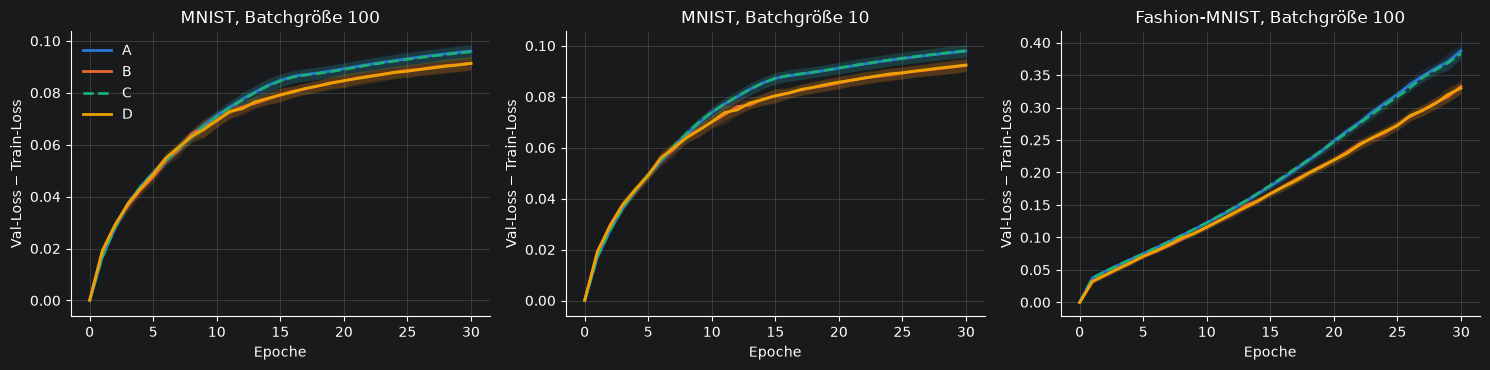

In [4]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 3.8), squeeze=False)
for ax, (name, df) in zip(axes[0], results.items()):
    for variant in SHUFFLE_VARIANTS:
        curve = df[df["variant"] == variant].groupby("epoch")["gap"].agg(["mean", "std"])
        ax.plot(curve.index, curve["mean"], STYLES.get(variant, "-"), color=COLORS[variant], lw=2, label=variant)
        ax.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], color=COLORS[variant], alpha=0.15, lw=0)
    ax.set(xlabel="Epoche", ylabel="Val-Loss − Train-Loss", title=TITLES[name])
    ax.tick_params(labelleft=True)
    style_axes(ax)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
save(fig, "generalization_gap")

Lesehilfe: Ein kleinerer Gap bedeutet, dass das Modell auf neuen Daten ähnlich gut abschneidet wie im Training. Weil die Varianten unterschiedlich schnell lernen, vergleicht diese Abbildung in jeder Epoche aber Modelle mit unterschiedlichem Trainingsstand. Das korrigiert Abschnitt 3.

**Ergebnis:** Bis etwa Epoche 8 ist der Gap aller Varianten gleich, danach wächst er bei A und C schneller. Gap in der letzten Epoche (Mittelwert über die Seeds):

| Experiment | A | B | D | B, D gegenüber A |
|---|---|---|---|---|
| MNIST, Batchgröße 100 | 0,096 | 0,091 | 0,091 | etwa −5 % |
| MNIST, Batchgröße 10 | 0,098 | 0,092 | 0,093 | etwa −6 % |
| Fashion-MNIST, Batchgröße 100 | 0,387 | 0,333 | 0,330 | etwa −14 % |

Bei B und D ist der Gap in 19 bzw. 20 von 20 Seeds kleiner als bei A (Abschnitt 5). Fashion-MNIST hat insgesamt einen etwa viermal so großen Gap wie MNIST, und dort ist auch der Unterschied zwischen den Varianten am größten.

## 3 Val-Loss bei gleichem Train-Loss

Jeder Punkt einer Kurve ist eine Epoche, gemittelt über die Seeds (Train-Loss geometrisch, Val-Loss arithmetisch). Die x-Achse ist umgedreht, das Training läuft also von links nach rechts. Die gestrichelte Linie markiert das gemeinsame Train-Loss-Niveau, an dem `val_loss_at_common_train_loss` gemessen wird.

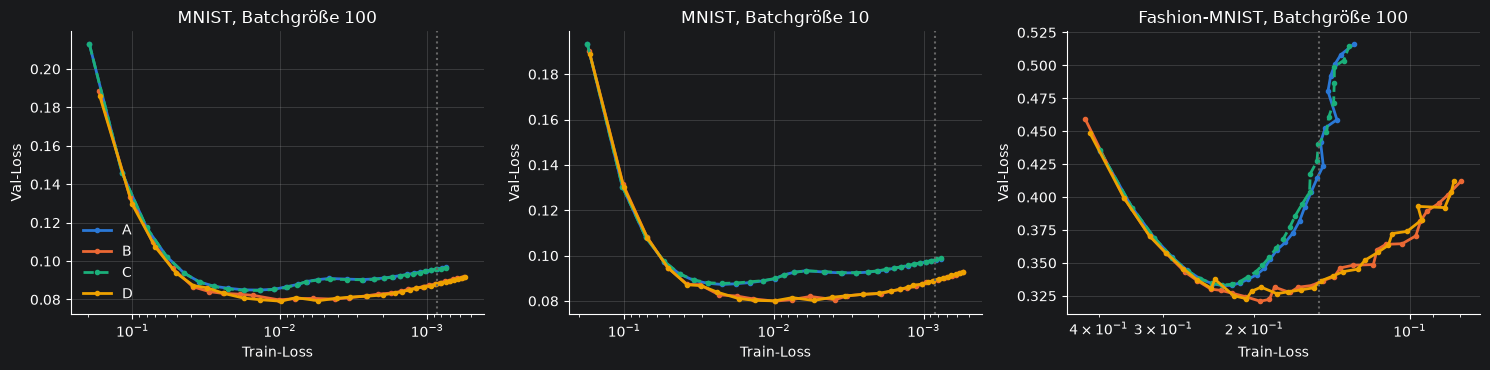

In [5]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 3.8), squeeze=False)
for ax, (name, df) in zip(axes[0], results.items()):
    for variant in SHUFFLE_VARIANTS:
        sub = df[(df["variant"] == variant) & (df["epoch"] > 0)]
        curve = sub.groupby("epoch").agg(train_loss=("train_loss", lambda s: np.exp(np.log(s).mean())), val_loss=("val_loss", "mean"))
        ax.plot(curve["train_loss"], curve["val_loss"], STYLES.get(variant, "-"), color=COLORS[variant], lw=2, marker="o", ms=3, label=variant)
    ax.axvline(levels[name], color="0.4", ls=":", lw=1.5)
    ax.set(xscale="log", xlabel="Train-Loss", ylabel="Val-Loss", title=TITLES[name])
    ax.invert_xaxis()
    style_axes(ax)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
save(fig, "val_vs_train_loss")

Lesehilfe: Die Kurven zeigen den Validierungs-Fehler im Verhältnis zum reinen Trainingsfortschritt (Train-Loss, von links nach rechts). Je tiefer eine Kurve liegt, desto besser generalisiert das Modell bei exakt gleichem Anpassungsgrad an die Trainingsdaten, ganz gleich, wie viele Epochen es dafür gebraucht hat.

**Ergebnis:** Bei gleichem Train-Loss liegt der Val-Loss von B und D in allen drei Experimenten unter dem von A und C:

| Experiment | Train-Loss-Niveau | A | B | D | B, D gegenüber A |
|---|---|---|---|---|---|
| MNIST, Batchgröße 100 | 0,00086 | 0,0959 | 0,0883 | 0,0880 | etwa −8 % |
| MNIST, Batchgröße 10 | 0,00084 | 0,0980 | 0,0889 | 0,0891 | etwa −9 % |
| Fashion-MNIST, Batchgröße 100 | 0,150 | 0,420 | 0,334 | 0,333 | etwa −20 % |

Der Vorteil von B und D ist also nicht nur, dass sie schneller trainieren: Bei gleich guter Anpassung an die Trainingsdaten generalisieren sie besser. Bei MNIST verlaufen die Kurven bis zu einem Train-Loss von etwa 0,03 fast identisch und trennen sich erst in der Overfitting-Phase. Bei Fashion-MNIST knickt die Kurve von A und C fast senkrecht nach oben: Der Val-Loss steigt weiter, während der Train-Loss kaum noch fällt. Weil die Kurve an der Messstelle so steil ist, streut der Wert von A dort auch stärker über die Seeds (± 0,03 gegenüber ± 0,01 bei B und D).

## 4 Beste Val-Accuracy und Streuung über die Seeds

Jeder Punkt ist ein Seed, der schwarze Strich der Mittelwert. Die y-Achsen sind pro Experiment unterschiedlich skaliert.

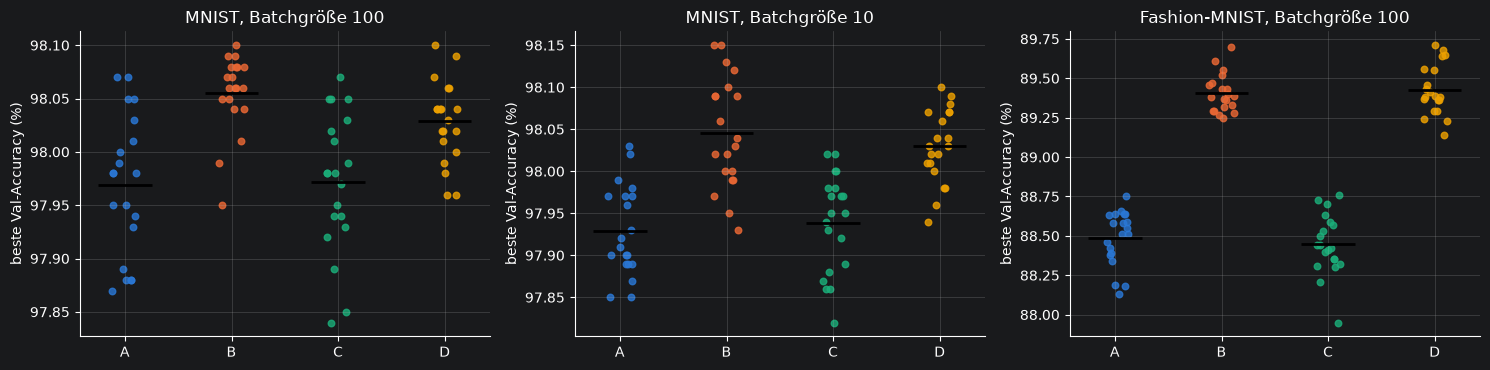

In [6]:
fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.8), squeeze=False)
rng = np.random.default_rng(0)
for ax, (name, m) in zip(axes[0], metrics.items()):
    for x, variant in enumerate(SHUFFLE_VARIANTS):
        values = m.loc[variant, "best_val_acc"] * 100
        ax.scatter(x + rng.uniform(-0.12, 0.12, len(values)), values, s=22, color=COLORS[variant], alpha=0.8)
        ax.hlines(values.mean(), x - 0.25, x + 0.25, color="black", lw=2)
    ax.set_xticks(range(len(SHUFFLE_VARIANTS)), SHUFFLE_VARIANTS)
    ax.set(ylabel="beste Val-Accuracy (%)", title=TITLES[name])
    style_axes(ax)
fig.tight_layout()
save(fig, "best_val_acc")

Lesehilfe: Jeder Punkt steht für die höchste Genauigkeit eines einzelnen Trainingsdurchlaufs, der schwarze Strich markiert den Durchschnitt. Liegen die Punkte weiter oben, erzielt diese Variante insgesamt eine höhere Genauigkeit. Liegen sie auf der y-Achse eng beisammen, ist die Leistung der Variante stabiler und hängt weniger von einer zufällig guten Initialisierung ab.

#### Übersicht aller Kennzahlen pro Variante, Mittelwert ± Standardabweichung über die Seeds (Accuracies in %):

In [7]:
ACC_COLUMNS = ["best_val_acc", "test_acc_at_best", "acc_gap_last_epoch"]
EPOCH_COLUMNS = ["best_val_acc_epoch", "min_val_loss_epoch"]


def summary_table(m: pd.DataFrame) -> pd.DataFrame:
    scaled = m.copy()
    scaled[ACC_COLUMNS] *= 100
    grouped = scaled.groupby("variant")
    mean, std = grouped.mean(), grouped.std()
    digits = {column: 2 if column in ACC_COLUMNS else 1 if column in EPOCH_COLUMNS else 4 for column in m.columns}
    return pd.DataFrame(
        {column: [f"{mean.loc[v, column]:.{digits[column]}f} ± {std.loc[v, column]:.{digits[column]}f}" if pd.notna(mean.loc[v, column]) else "" for v in VARIANT_NAMES] for column in m.columns},
        index=pd.Index(VARIANT_NAMES, name="Variante"),
    )


for name, m in metrics.items():
    print(TITLES[name])
    display(summary_table(m))

MNIST, Batchgröße 100


,best_val_acc,best_val_acc_epoch,test_acc_at_best,min_val_loss,min_val_loss_epoch,gap_last_epoch,acc_gap_last_epoch,val_loss_at_common_train_loss
Variante,,,,,,,,
A,97.97 ± 0.07,24.9 ± 4.6,98.02 ± 0.08,0.0845 ± 0.0022,9.7 ± 0.9,0.0961 ± 0.0026,2.05 ± 0.07,0.0959 ± 0.0025
B,98.06 ± 0.04,21.2 ± 4.9,98.12 ± 0.05,0.0771 ± 0.0025,9.7 ± 2.1,0.0914 ± 0.0024,1.99 ± 0.05,0.0883 ± 0.0020
C,97.97 ± 0.07,24.6 ± 4.3,98.02 ± 0.08,0.0844 ± 0.0022,9.8 ± 1.1,0.0958 ± 0.0026,2.05 ± 0.07,0.0957 ± 0.0026
D,98.03 ± 0.04,20.1 ± 5.1,98.08 ± 0.07,0.0768 ± 0.0016,9.8 ± 1.6,0.0913 ± 0.0025,2.01 ± 0.05,0.0880 ± 0.0024
E,55.73 ± 2.87,30.0 ± 0.0,56.13 ± 2.77,2.2539 ± 0.0844,13.4 ± 15.3,0.0705 ± 0.0161,0.79 ± 0.20,


MNIST, Batchgröße 10


,best_val_acc,best_val_acc_epoch,test_acc_at_best,min_val_loss,min_val_loss_epoch,gap_last_epoch,acc_gap_last_epoch,val_loss_at_common_train_loss
Variante,,,,,,,,
A,97.93 ± 0.05,26.6 ± 3.5,98.04 ± 0.06,0.0871 ± 0.0022,8.2 ± 0.8,0.0979 ± 0.0024,2.08 ± 0.06,0.0980 ± 0.0025
B,98.05 ± 0.07,21.4 ± 5.7,98.11 ± 0.06,0.0771 ± 0.0019,10.2 ± 1.8,0.0922 ± 0.0025,2.00 ± 0.08,0.0889 ± 0.0024
C,97.94 ± 0.06,25.7 ± 3.9,98.04 ± 0.07,0.0874 ± 0.0022,8.5 ± 1.2,0.0980 ± 0.0025,2.08 ± 0.06,0.0982 ± 0.0026
D,98.03 ± 0.04,21.5 ± 4.8,98.10 ± 0.07,0.0778 ± 0.0024,9.8 ± 1.5,0.0925 ± 0.0025,2.03 ± 0.04,0.0891 ± 0.0023
E,42.22 ± 2.17,30.0 ± 0.0,43.23 ± 2.06,2.3114 ± 0.0049,0.0 ± 0.0,0.0712 ± 0.0104,1.06 ± 0.28,


Fashion-MNIST, Batchgröße 100


,best_val_acc,best_val_acc_epoch,test_acc_at_best,min_val_loss,min_val_loss_epoch,gap_last_epoch,acc_gap_last_epoch,val_loss_at_common_train_loss
Variante,,,,,,,,
A,88.49 ± 0.17,20.7 ± 7.9,88.14 ± 0.18,0.3322 ± 0.0034,8.2 ± 0.8,0.3874 ± 0.0099,7.02 ± 0.27,0.4200 ± 0.0321
B,89.40 ± 0.12,21.2 ± 4.4,89.01 ± 0.24,0.3131 ± 0.0049,12.0 ± 1.7,0.3326 ± 0.0108,8.11 ± 0.25,0.3343 ± 0.0110
C,88.45 ± 0.19,19.7 ± 7.3,88.13 ± 0.26,0.3327 ± 0.0041,8.4 ± 1.0,0.3833 ± 0.0100,7.01 ± 0.26,0.4301 ± 0.0406
D,89.43 ± 0.16,22.9 ± 5.1,89.05 ± 0.23,0.3131 ± 0.0038,11.4 ± 1.7,0.3297 ± 0.0087,8.05 ± 0.28,0.3334 ± 0.0113
E,39.15 ± 2.30,27.0 ± 2.2,38.63 ± 2.38,2.2831 ± 0.0528,4.7 ± 9.7,0.0151 ± 0.0170,-0.38 ± 0.18,


**Ergebnis:**

- **Beste Val-Accuracy:** B und D liegen bei MNIST um 0,06-0,12 Prozentpunkte über A (97,9 % gegenüber 98,0-98,1 %), bei Fashion-MNIST um 0,9 Prozentpunkte (88,5 % gegenüber 89,4 %). Die Test-Accuracy in derselben Epoche zeigt dasselbe Bild (Fashion-MNIST: 88,1 % gegenüber 89,0 %). Der Effekt ist also kein Artefakt davon, dass die Epoche anhand von Val ausgewählt wird.
- **Streuung:** Bei MNIST ist der Effekt etwa so groß wie die Standardabweichung über die Seeds (0,04-0,07 Prozentpunkte). In der Abbildung überlappen die Punktwolken deshalb; sichtbar wird der Effekt erst im gepaarten Vergleich (Abschnitt 5). Bei Fashion-MNIST ist er fünf- bis siebenmal so groß wie die Streuung, die Punktwolken sind getrennt.
- **Epochen:** Bei Fashion-MNIST liegt das Minimum des Val-Loss bei B und D später (Epoche 11-12 statt 8), bei MNIST mit Batchgröße 10 ebenso (Epoche 10 statt 8). Das Overfitting setzt also später ein, eine typische Signatur von Regularisierung. Bei MNIST mit Batchgröße 100 gibt es diesen Unterschied nicht.
- **Accuracy-Gap:** Bei Fashion-MNIST ist der Accuracy-Gap von B und D *größer* als bei A (8,1 statt 7,0 Prozentpunkte), obwohl ihr Loss-Gap kleiner ist. Grund: B und D treffen die Trainingsdaten besser (Train-Accuracy in Epoche 30: 97,1 % gegenüber 95,2 %), ihre Val-Accuracy steigt aber nicht im selben Maß mit. Ein Gap in einer festen Epoche hängt also stark vom Trainingsstand ab; deshalb ist Abschnitt 3 der fairere Vergleich.
- **C** liegt in allen Kennzahlen auf A. **E** wird in Abschnitt 6 besprochen.

## 5 Gepaarte Vergleiche

Für jedes Paar von Varianten wird pro Seed die Differenz gebildet und dann über die Seeds gemittelt (`paired_comparison` in `analysis.py`). Angegeben sind:

- **Differenz**: Mittelwert der Differenzen, mit 95 %-Konfidenzintervall (t-Verteilung).
- **Seeds mit Differenz > 0**: in wie vielen Seeds die erste Variante den höheren Wert hat.
- **p (Wilcoxon)**: Wilcoxon-Vorzeichen-Rang-Test, prüft, ob die Differenzen systematisch von 0 abweichen, ohne Normalverteilung vorauszusetzen.

Beim Lesen der p-Werte beachten: Hier werden viele Vergleiche gleichzeitig gerechnet. Ein einzelnes p um 0,03 ist bei so vielen Tests auch durch Zufall zu erwarten. Belastbar sind Effekte, die über mehrere Kennzahlen hinweg konsistent auftreten.

Die Vergleiche:
- **B − A** und **D − A**: bringt Shuffling überhaupt etwas?
- **D − B**: bringen neue Batch-Zusammensetzungen etwas über das Mischen der Reihenfolge hinaus?
- **C − A**: Kontrolle, sollte ≈ 0 sein.

In [8]:
PAIRS = [("B", "A"), ("D", "A"), ("D", "B"), ("C", "A")]
COMPARED = ["best_val_acc", "test_acc_at_best", "min_val_loss", "val_loss_at_common_train_loss", "gap_last_epoch"]
comparisons = {name: paired_comparison(m, PAIRS, COMPARED) for name, m in metrics.items()}

for name, table in comparisons.items():
    print(TITLES[name])
    display(table.style.format({"Differenz": "{:+.5f}", "95%-KI unten": "{:+.5f}", "95%-KI oben": "{:+.5f}", "p (Wilcoxon)": "{:.4f}"}))

MNIST, Batchgröße 100


MNIST, Batchgröße 10


Fashion-MNIST, Batchgröße 100


#### Die wichtigsten Vergleiche als Abbildung: Punkt = mittlere Differenz, Balken = 95 %-Konfidenzintervall. Ein Balken, der die Nulllinie nicht schneidet, ist ein systematischer Unterschied. Bei der Accuracy bedeutet rechts von 0 "erste Variante besser", beim Val-Loss links von 0.

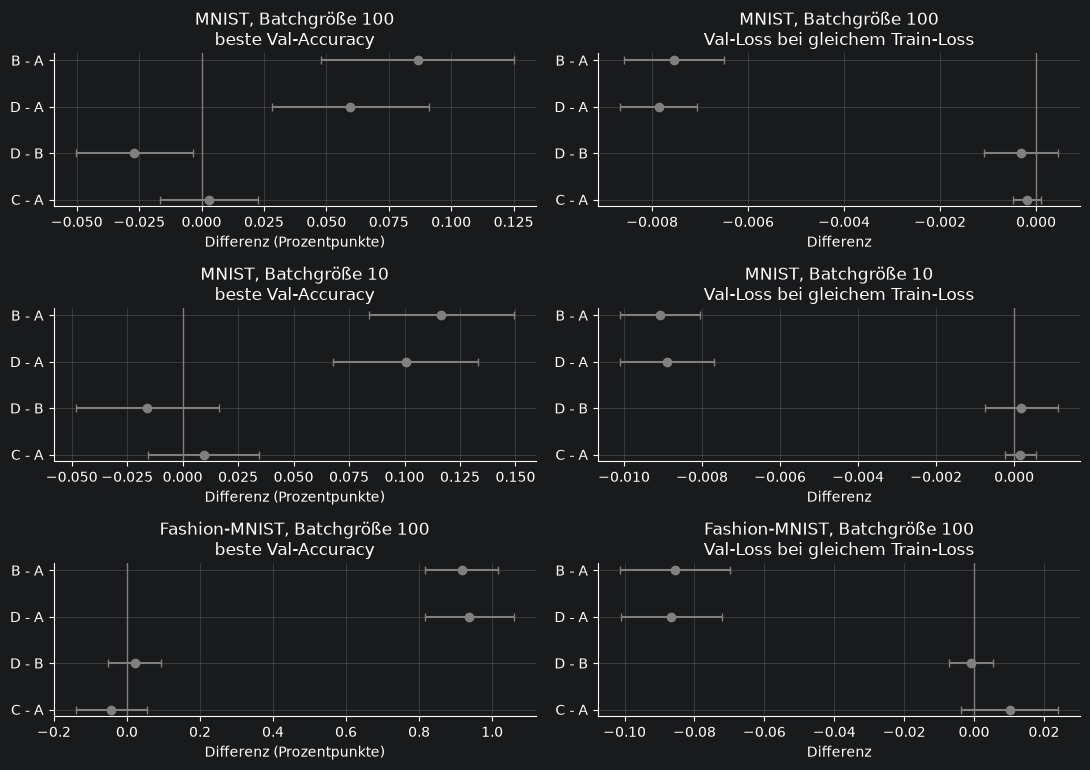

In [9]:
FOREST_METRICS = {"best_val_acc": ("beste Val-Accuracy", 100, "Differenz (Prozentpunkte)"), "val_loss_at_common_train_loss": ("Val-Loss bei gleichem Train-Loss", 1, "Differenz")}

fig, axes = plt.subplots(len(comparisons), len(FOREST_METRICS), figsize=(11, 2.6 * len(comparisons)), squeeze=False)
for row, (name, table) in enumerate(comparisons.items()):
    for col, (metric, (label, scale, xlabel)) in enumerate(FOREST_METRICS.items()):
        ax = axes[row, col]
        sub = table.xs(metric, level="Kennzahl").iloc[::-1]
        y = np.arange(len(sub))
        ax.errorbar(sub["Differenz"] * scale, y, xerr=[(sub["Differenz"] - sub["95%-KI unten"]) * scale, (sub["95%-KI oben"] - sub["Differenz"]) * scale],
                    fmt="o", color="gray", ecolor="gray", capsize=3, ms=6)
        ax.axvline(0, color="0.5", lw=1)
        ax.set_yticks(y, sub.index)
        ax.set(xlabel=xlabel, title=f"{TITLES[name]}\n{label}")
        style_axes(ax)
fig.tight_layout()
save(fig, "paired_differences")

**Ergebnis:**

- **B − A und D − A:** In allen drei Experimenten systematisch und über alle Kennzahlen hinweg konsistent. Beim Val-Loss bei gleichem Train-Loss ist A in keinem einzigen Seed besser (0/20), beim Gap in höchstens einem. Alle p-Werte dieser Loss-Kennzahlen liegen unter 0,001. Bei der Accuracy gewinnen B und D in 15-20 von 20 Seeds.
- **D − B:** Kein belastbarer Unterschied. Bei MNIST mit Batchgröße 10 und bei Fashion-MNIST schneiden alle Konfidenzintervalle die Null. Bei MNIST mit Batchgröße 100 liegt D bei der Accuracy knapp hinter B (−0,03 Prozentpunkte Val, −0,04 Test, p ≈ 0,03-0,04), bei den Loss-Kennzahlen aber nicht. Feste Batch-Zusammensetzungen schaden nicht, solange die Reihenfolge der Batches gemischt wird.
- **C − A:** Wie erwartet ≈ 0, alle Konfidenzintervalle schneiden die Null. C ist mathematisch dasselbe Training wie A; die kleinen Abweichungen entstehen, weil sich die Summationsreihenfolge im Batch-Mittelwert ändert und sich diese Rundungsunterschiede über tausende Schritte aufschaukeln. C − A zeigt damit, wie groß reines Rauschen zwischen zwei Läufen mit denselben Startgewichten ist.
- **Zum Mehrfachtesten:** In den 30 Vergleichen, in denen kein Effekt zu erwarten ist (D − B und C − A), sind bei p < 0,05 im Schnitt 1,5 Zufallstreffer zu erwarten. Gefunden wurden drei: die beiden Accuracy-Werte von D − B bei MNIST mit Batchgröße 100 (Val- und Test-Accuracy hängen eng zusammen, das ist eher ein Treffer als zwei) und der Gap von C − A bei MNIST mit Batchgröße 100 (p = 0,044, Differenz 0,0003). Das passt zu Zufall und ist kein Befund.

## 6 Variante E: nach Klasse sortiert

Val-Accuracy pro Epoche für A (Referenz) und E, Mittelwert ± Standardabweichung über die Seeds.

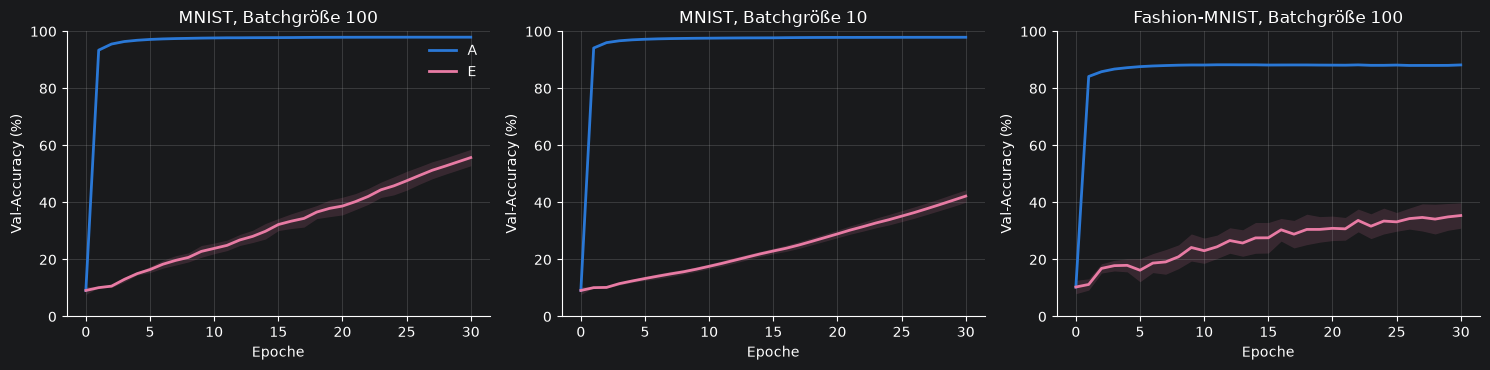

In [10]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 3.8), squeeze=False)
for ax, (name, df) in zip(axes[0], results.items()):
    for variant in ["A", "E"]:
        curve = df[df["variant"] == variant].groupby("epoch")["val_acc"].agg(["mean", "std"]) * 100
        ax.plot(curve.index, curve["mean"], color=COLORS[variant], lw=2, label=variant)
        ax.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], color=COLORS[variant], alpha=0.15, lw=0)
    ax.set(xlabel="Epoche", ylabel="Val-Accuracy (%)", ylim=(0, 100), title=TITLES[name])
    style_axes(ax)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
save(fig, "variant_e")

Lesehilfe: Gemessen wird immer am Ende einer Epoche. Bei E hat das Modell da zuletzt nur die letzte Klasse gesehen (bei Batchgröße 100 etwa 50 Schritte lang, bei Batchgröße 10 etwa 500) und sagt überwiegend diese voraus.

**Ergebnis:** E scheitert in allen drei Experimenten. Die beste Val-Accuracy liegt bei 55,7 % (MNIST, Batchgröße 100), 42,2 % (MNIST, Batchgröße 10) und 39,2 % (Fashion-MNIST), gegenüber 98,0 % bzw. 88,5 % bei A. Die Accuracy steigt über die Epochen zwar langsam an und hat nach 30 Epochen ihr Maximum noch nicht erreicht (bei MNIST ist die beste Epoche in jedem Seed die letzte). Innerhalb jeder Epoche verlernt das Modell aber, was es über die früheren Klassen gelernt hat. Der niedrigste Val-Loss liegt bei 2,0-2,3, also etwa bei ln 10 ≈ 2,30, dem Loss eines Modells, das alle Klassen gleich wahrscheinlich vorhersagt. In Epoche 30 liegt er sogar darüber (2,4-3,7), weil das Modell selbstsicher die zuletzt gesehene Klasse vorhersagt.

Wichtig für die Frage nach dem Generalization Gap: E hat den kleinsten Gap aller Varianten (Fashion-MNIST: 0,015, der Accuracy-Gap ist dort sogar negativ). Das ist keine gute Generalisierung, sondern Underfitting: Das Modell ist auf den Trainingsdaten genauso schlecht wie auf den Validierungsdaten (Train-Accuracy in Epoche 30: 35-57 %). Ein kleiner Gap ist nur zusammen mit einem niedrigen Val-Loss ein gutes Zeichen.

## 7 Fazit

1. **Shuffling wirkt hier als Regularisierer.** B und D generalisieren in allen drei Experimenten besser als A: Der Val-Loss bei gleichem Train-Loss ist in jedem der 20 Seeds niedriger. Auf MNIST ist der Effekt klein (etwa +0,1 Prozentpunkte Val-Accuracy, −8 bis −9 % Val-Loss bei gleichem Train-Loss), auf Fashion-MNIST deutlich (+0,9 Prozentpunkte, −20 %).
2. **Je stärker das Modell overfittet, desto größer der Effekt.** Fashion-MNIST hat einen etwa viermal so großen Gap wie MNIST, und dort bringt Shuffling am meisten.
3. **Entscheidend ist, dass sich die Reihenfolge der Schritte ändert, nicht die Zusammensetzung der Batches.** D ist in keinem Experiment robust besser als B, auch nicht bei Batchgröße 10. Die Reihenfolge innerhalb eines Batches spielt keine Rolle (C ≈ A), weil der Gradient über den Batch gemittelt wird.
4. **Eine schlechte feste Reihenfolge ist kein Regularisierungsproblem, sondern verhindert das Lernen** (E). Ein kleiner Gap kann auch Underfitting bedeuten.

**Grenzen:** Ein Netz (MLP 784-256-256-10), plain SGD ohne Momentum mit fester Lernrate, 30 Epochen, zwei Datensätze im selben Format und ein fester Validierungs-Split. A trainiert auf der Originalreihenfolge der Datensätze, in der die Klassen bereits gut durchmischt sind; A steht also für eine feste, aber zufällige Reihenfolge. Ob der Effekt mit Momentum oder Adam, Lernraten-Schedules, zusätzlicher Regularisierung (Dropout, L2-Regularisierung) oder größeren Modellen bestehen bleibt, ist offen.